# OFDM TX/RX — Pipeline robusta (HackRF) com detecção de runs inválidos + retries


## 1) Imports


In [12]:
import os, sys, time, json, subprocess, re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


## 2) Globais


In [13]:
WORKDIR = os.getcwd()

TX_HACKRF = "hackrf=0"
RX_HACKRF = "hackrf=1"

SAMP_RATE = 1800000
CENTER_FREQ = 907980000.0

TX_PAYLOAD = os.path.join(WORKDIR, "tx_payload.bin")
RX_PAYLOAD = os.path.join(WORKDIR, "rx_payload.bin")
RX_IQ_FILE = os.path.join(WORKDIR, "rx_iq.cfile")

KNOWN_TEXT = "Hello World\n"
KNOWN_REPEATS = 200
KNOWN_MIN_COUNT = 5

RX_MIN_BYTES = 200

INVALID_STDERR_PATTERNS = [
    r"Buffer too small for min_noutput_items",
    r"thread_body_wrapper\s*:error",
    r"OOOO+",
]
WARN_STDERR_PATTERNS = [r"UUUU+"]

print("TX_PAYLOAD:", TX_PAYLOAD)
print("RX_PAYLOAD:", RX_PAYLOAD)

_RUNNER_PATH = os.path.join(WORKDIR, "_ofdm_runner_tmp.py")


TX_PAYLOAD: /home/pesquisa/HEst_Prototyping/tx_payload.bin
RX_PAYLOAD: /home/pesquisa/HEst_Prototyping/rx_payload.bin


## 3) Gerar runner (script isolado TX+RX)


In [14]:
def stderr_has(patterns, stderr_text):
    for pat in patterns:
        if re.search(pat, stderr_text, flags=re.IGNORECASE):
            return True
    return False

def run_experiment_subprocess(seconds=6.0, noise_voltage=0.0, record_iq=False, write_known=True,
                              tx_args=None, rx_args=None, extra_args=None):
    if tx_args is None:
        tx_args = TX_HACKRF
    if rx_args is None:
        rx_args = RX_HACKRF

    cmd = [sys.executable, _RUNNER_PATH,
           "--seconds", str(seconds),
           "--noise_voltage", str(noise_voltage),
           "--tx_args", tx_args,
           "--rx_args", rx_args,
           "--known_text", KNOWN_TEXT,
           "--known_repeats", str(KNOWN_REPEATS)]
    if record_iq:
        cmd.append("--record_iq")
    if write_known:
        cmd.append("--write_known")
    if extra_args:
        cmd.extend(extra_args)

    p = subprocess.run(cmd, capture_output=True, text=True)
    stdout = p.stdout
    stderr = p.stderr

    result = None
    for line in stdout.splitlines()[::-1]:
        line = line.strip()
        if not line:
            continue
        try:
            result = json.loads(line)
            break
        except Exception:
            continue

    return {"returncode": p.returncode, "stdout": stdout, "stderr": stderr, "result": result}

def validate_run(run):
    res = run.get("result")
    if res is None:
        return (False, "runner não retornou JSON")
    if run["returncode"] != 0:
        return (False, f"returncode != 0 ({run['returncode']})")
    if not res.get("ok", False):
        return (False, "runner capturou exceção ao rodar flowgraphs")
    if stderr_has(INVALID_STDERR_PATTERNS, run["stderr"]):
        return (False, "stderr contém erro hard (Buffer/OOOO/thread error)")
    if res.get("rx_size", 0) < RX_MIN_BYTES:
        return (False, f"rx_size muito pequeno ({res.get('rx_size',0)})")
    if res.get("known_pattern_count_in_rx_head", 0) < KNOWN_MIN_COUNT:
        return (False, f"padrão conhecido apareceu pouco (count={res.get('known_pattern_count_in_rx_head',0)})")
    if stderr_has(WARN_STDERR_PATTERNS, run["stderr"]):
        return (True, "válido (com warning: UUUU)")
    return (True, "válido")

def run_with_retries(max_tries=5, sleep_between=0.1, **kwargs):
    last = None
    for k in range(1, max_tries+1):
        run = run_experiment_subprocess(**kwargs)
        last = run
        ok, reason = validate_run(run)
        print(f"[try {k}/{max_tries}] {reason}")
        if ok:
            run["validation_reason"] = reason
            return run
        time.sleep(sleep_between)
    last["validation_reason"] = "falhou após retries"
    return last


## 5) Sanity check (sem ruído) + diagnóstico (offset, BER alinhado)


In [ ]:
def hexdump(b: bytes, n=64):
    b = b or b""
    h = " ".join(f"{x:02x}" for x in b[:n])
    a = "".join(chr(x) if 32 <= x < 127 else "." for x in b[:n])
    return f"{h}\n|{a}|"

def ber_bits(tx: bytes, rx: bytes):
    n = min(len(tx), len(rx))
    if n == 0:
        return None
    a = np.frombuffer(tx[:n], dtype=np.uint8)
    b = np.frombuffer(rx[:n], dtype=np.uint8)
    x = np.bitwise_xor(a, b)
    return float(np.unpackbits(x).sum()) / float(n * 8)

def safe_text(b: bytes, n=160):
    return (b or b"").decode("utf-8", errors="replace")[:n]

run0 = run_with_retries(max_tries=5, seconds=6.0, noise_voltage=0.0, record_iq=False, write_known=True)
print("validation:", run0.get("validation_reason"))
print("stderr tail:")
print("\n".join(run0.get("stderr","").splitlines()[-10:]))

res0 = run0.get("result")
print(json.dumps(res0, indent=2) if res0 else "<no result>")

if res0:
    off = int(res0.get("offset") or 0)
    print("TX head hex:", res0.get("tx_head_hex"))
    print("RX head hex:", res0.get("rx_head_hex"))
    print("offset:", off, "score:", res0.get("score"))
    print("BER bruto:", res0.get("ber_raw"))
    print("BER alinhado:", res0.get("ber_aligned"))

    tx = Path("tx_payload.bin").read_bytes() if Path("tx_payload.bin").exists() else b""
    rx = Path("rx_payload.bin").read_bytes() if Path("rx_payload.bin").exists() else b""
    rx_al = rx[off:] if off >= 0 else rx

    print("\nTX text:", repr(safe_text(tx)))
    print("RX text (al):", repr(safe_text(rx_al)))

    print("\nTX hexdump:\n", hexdump(tx, 64))
    print("RX hexdump (al):\n", hexdump(rx_al, 64))



[try 1/5] stderr contém erro hard (Buffer/OOOO/thread error)
[try 2/5] válido (com warning: UUUU)
validation: válido (com warning: UUUU)
stderr tail:
gr-osmosdr 0.2.0.0 (0.2.0) gnuradio 3.10.11.0
built-in source types: file fcd rtl rtl_tcp uhd hackrf rfspace airspy soapy redpitaya 
Using HackRF One with firmware v2.0.1
gr-osmosdr 0.2.0.0 (0.2.0) gnuradio 3.10.11.0
built-in sink types: uhd hackrf soapy redpitaya file 
Using HackRF One with firmware v2.0.0
UUUU
{
  "ok": true,
  "seconds": 6.0,
  "noise_voltage": 0.0,
  "dt": 7.594275712966919,
  "tx_size": 2400,
  "rx_size": 166601,
  "tx_head_hex": "48656c6c6f20576f726c640a48656c6c6f20576f726c640a48656c6c6f20576f726c640a48656c6c6f20576f726c640a48656c6c6f20576f726c640a48656c6c",
  "rx_head_hex": "f47152e39686a53c513d53c3cdc6cd0c1061f2c3edb687fcca49a4d7eaf65e78d1c99507795e3268f3810d84b749e36a51a40ff08bb4f0c5534d0861abcbd6c9",
  "known_pattern_count_in_rx_head": 6,
  "ber_raw": 0.4203645833333333,
  "ber_aligned": 0.3353174603174603,
  "o

## 6) Varredura BER vs SNR (AWGN no RX) — repetição por ponto + retries


In [16]:
def snr_db_to_noise_voltage(snr_db):
    return 10 ** (-snr_db / 20.0)

def sweep(snr_db_list, seconds=6.0, repetitions=3, max_tries=5):
    rows = []
    for snr_db in snr_db_list:
        nv = snr_db_to_noise_voltage(snr_db)
        bers_al = []
        valids = 0
        for _ in range(repetitions):
            run = run_with_retries(max_tries=max_tries, seconds=seconds, noise_voltage=nv, record_iq=False, write_known=True)
            ok, _ = validate_run(run)
            if ok:
                valids += 1
                bers_al.append(run["result"].get("ber_aligned"))
            else:
                bers_al.append(np.nan)
        rows.append({
            "snr_db": snr_db,
            "noise_voltage": nv,
            "valid_runs": valids,
            "ber_aligned_mean": float(np.nanmean(bers_al)),
            "ber_aligned_std": float(np.nanstd(bers_al)),
            "bers_aligned": bers_al,
        })
        print(f"SNR={snr_db:>3} dB | nv={nv:.6f} | valid={valids}/{repetitions} | BER_al_mean={rows[-1]['ber_aligned_mean']:.3e}")
    return rows

snr_db_list = [30, 25, 20, 15]
rows = sweep(snr_db_list, seconds=2, repetitions=5, max_tries=8)


[try 1/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] stderr contém erro hard (Buffer/OOOO/thread error)
[try 2/8] stderr contém erro hard (Buffer/OOOO/thread error)
[try 3/8] stderr contém erro hard (Buffer/OOOO/thread error)
[try 4/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] stderr contém erro hard (Buffer/OOOO/thread error)
[try 2/8] stderr contém erro hard (Buffer/OOOO/thread error)
[try 3/8] válido (com warning: UUUU)
SNR= 30 dB | nv=0.031623 | valid=5/5 | BER_al_mean=3.246e-01
[try 1/8] válido (com warning: UUUU)
[try 1/8] stderr contém erro hard (Buffer/OOOO/thread error)
[try 2/8] stderr contém erro hard (Buffer/OOOO/thread error)
[try 3/8] stderr contém erro hard (Buffer/OOOO/thread error)
[try 4/8] stderr contém erro hard (Buffer/OOOO/thread error)
[try 5/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
SNR= 25 dB | nv=0.05

## 7) Gráficos finais


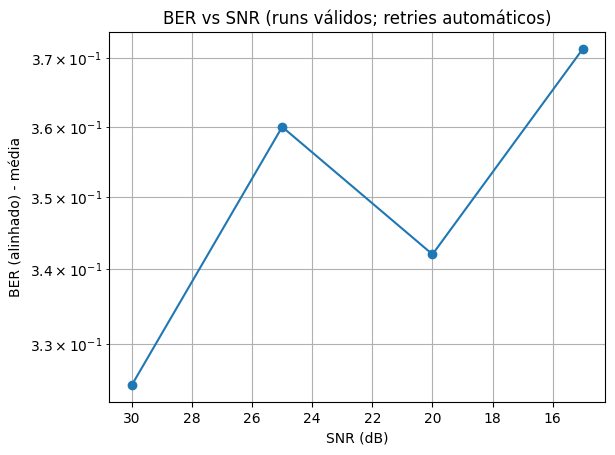

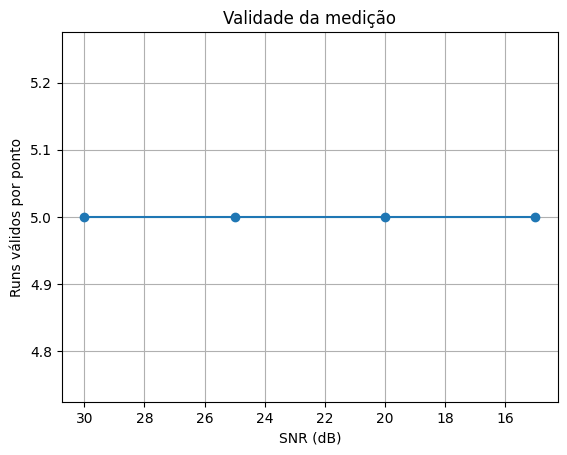

In [17]:
snr = [r["snr_db"] for r in rows]
ber = [r["ber_aligned_mean"] for r in rows]
valids = [r["valid_runs"] for r in rows]

plt.figure()
plt.semilogy(snr, ber, marker="o")
plt.gca().invert_xaxis()
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("BER (alinhado) - média")
plt.title("BER vs SNR (runs válidos; retries automáticos)")
plt.show()

plt.figure()
plt.plot(snr, valids, marker="o")
plt.gca().invert_xaxis()
plt.grid(True)
plt.xlabel("SNR (dB)")
plt.ylabel("Runs válidos por ponto")
plt.title("Validade da medição")
plt.show()
